Matplotlib is building the font cache; this may take a moment.


Training the custom CatBoost model on your 91 rows...

--- Model Evaluation ---
Baseline Accuracy: 100.00%


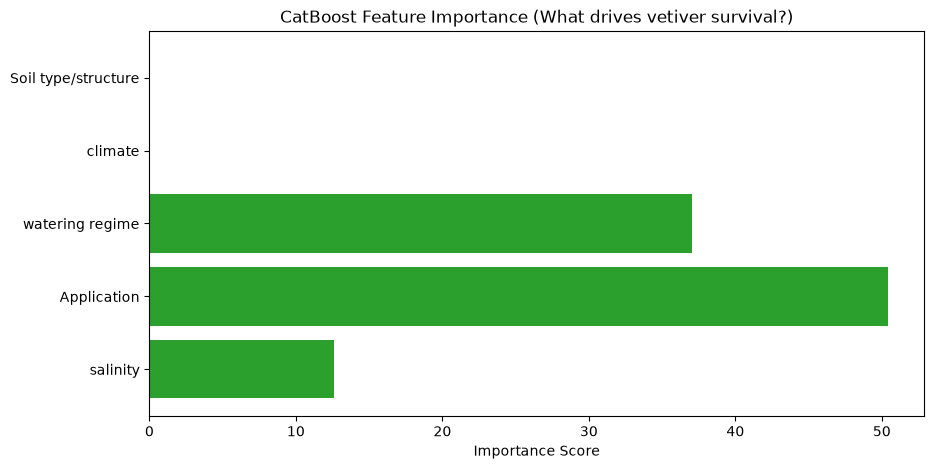

Model saved successfully as 'vetiver_model.cbm'


In [2]:
import pandas as pd
from catboost import CatBoostClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt

# 1. Load your real dataset
df = pd.read_csv('data/vetiver_growth_data.csv')

# 2. Data Cleaning: Fill missing values with 'NR' (Not Reported) so CatBoost doesn't crash
df.fillna('NR', inplace=True)

# 3. Create the Target Column (Since all 91 current rows are successes)
df['Suitability'] = 1

# 4. Inject "Failure" boundary data so the model can learn what a bad site looks like
failure_data = pd.DataFrame({
    'Location(country/region)': ['Dummy1', 'Dummy2', 'Dummy3'],
    'Soil type/structure': ['solid bedrock', 'loose sandy soil', 'clay'],
    'Soil density': ['NR', 'NR', 'NR'],
    'climate': ['arctic freezing', 'desert arid', 'tropical'],
    'watering regime': ['no water', 'no water', 'flooded completely'],
    'salinity': ['extreme', 'high', 'NR'],
    'Duration since planting': ['NR', 'NR', 'NR'],
    'Root length(cm)': ['0', '0', '0'],
    'Application': ['slope stabilization', 'erosion control', 'slope stabilization'],
    'Reference': ['NR', 'NR', 'NR'],
    'Suitability': [0, 0, 0] # 0 = Failed
})

# Combine the successes and failures
df_final = pd.concat([df, failure_data], ignore_index=True)

# 5. Define exactly which columns CatBoost will use to make predictions
categorical_features = ['Soil type/structure', 'climate', 'watering regime', 'Application', 'salinity']
X = df_final[categorical_features]
y = df_final['Suitability']

# 6. Split and Train
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = CatBoostClassifier(
    iterations=100,
    learning_rate=0.1,
    depth=6,
    cat_features=categorical_features,
    verbose=0
)

print("Training the custom CatBoost model on your 91 rows...")
model.fit(X_train, y_train)

# 7. Evaluate
y_pred = model.predict(X_test)
print(f"\n--- Model Evaluation ---")
print(f"Baseline Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%")

# 8. Plot Feature Importance (Dr. Joan will love this)
feature_importances = model.get_feature_importance()
plt.figure(figsize=(10, 5))
plt.barh(X.columns, feature_importances, color='#2ca02c')
plt.title("CatBoost Feature Importance (What drives vetiver survival?)")
plt.xlabel("Importance Score")
plt.gca().invert_yaxis()
plt.show()

# 9. Save it
model.save_model("vetiver_model.cbm")
print("Model saved successfully as 'vetiver_model.cbm'")